# 06 – Ngoại lai, gợi ý vị trí và triển khai (Deployment & Feedback)

1. Phát hiện cửa hàng "lạc loài" bằng **LOF** và **Isolation Forest**
2. **Gợi ý vị trí** mở quán: chấm điểm từng ô lưới 200 m cho từng loại hình
3. **Gợi ý loại hình** cho một vị trí bất kỳ (công cụ `src/recommend.py`)
4. **Sản phẩm cuối:** `stores_analyzed.csv` (tệp dữ liệu đã phân tích), GeoJSON cho web, từ điển dữ liệu
5. **Feedback:** bài học và vòng lặp cải tiến

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium

from src import cleaning as cl, geo, features as ft, viz

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
viz.set_style()
PROC = ROOT / "data" / "processed"
TABLES = viz.TABLE_DIR

import json
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from src import recommend as rc, clustering as cu

df = pd.read_csv(PROC / "stores_clean.csv")
df["type_group"] = [ft.primary_group(t, c) for t, c in zip(df["product_types"], df["category"])]
df["street"] = df["address"].map(cl.street_of)
df = (df.merge(pd.read_csv(PROC / "stores_clusters.csv"), on="storeId", how="left")
        .merge(pd.read_csv(PROC / "stores_features.csv").drop(columns=["storeName", "latitude", "longitude", "type_group", "is_hotspot"]),
               on="storeId", how="left")
        .merge(pd.read_csv(PROC / "stores_predictions.csv"), on="storeId", how="left"))
df = df.copy()
df["competitors_same_type_300m"] = ft.same_type_competitors(df, 300)
print(df.shape)

(3208, 134)


## 1. Cửa hàng "lạc loài": LOF và Isolation Forest

Một cửa hàng được coi là lạc loài nếu **vị trí** hoặc **loại hình so với xung quanh** của nó bất thường. Đặc trưng dùng (chuẩn hóa z-score):

| Đặc trưng | Bắt được trường hợp nào |
|---|---|
| `log(1 + n_total_100m)`, `log(1 + n_total_300m)` | quán ở nơi rất thưa |
| `log(dist_nearest_m)` | quán đứng một mình, cách xa quán khác |
| `dist_river_m` | quán ở rìa quận |
| `share_own_type_300m` | loại hình của quán gần như không có ở khu vực xung quanh |
| `n_types_unique_300m` | khu vực rất đơn điệu |

- **LOF** (n_neighbors = 20) so sánh mật độ cục bộ của một điểm với các láng giềng *trong không gian đặc trưng*.
- **Isolation Forest** (300 cây) đo số lần cắt cần thiết để cô lập một điểm.
- Cả hai đặt **contamination = 3%** (khoảng 96 cửa hàng). Đây là ngưỡng quy ước để xem xét thủ công, không phải tỉ lệ ngoại lai "thật".

In [2]:
own_share = np.array([df.loc[i, f"share_{ft.GROUP_SLUG[g]}_300m"] for i, g in enumerate(df["type_group"])])
O = pd.DataFrame({
    "log_n100": np.log1p(df["n_total_100m"]), "log_n300": np.log1p(df["n_total_300m"]),
    "log_dist_nearest": np.log(df["dist_nearest_m"] + 1), "dist_river_m": df["dist_river_m"],
    "share_own_type_300m": own_share, "n_types_unique_300m": df["n_types_unique_300m"],
})
Z = StandardScaler().fit_transform(O)
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.03)
df["lof_outlier"] = lof.fit_predict(Z) == -1
df["lof_score"] = -lof.negative_outlier_factor_
iso = IsolationForest(n_estimators=300, contamination=0.03, random_state=RANDOM_STATE).fit(Z)
df["if_outlier"] = iso.predict(Z) == -1
df["if_score"] = -iso.score_samples(Z)
df["outlier_both"] = df["lof_outlier"] & df["if_outlier"]
print(f"LOF: {df['lof_outlier'].sum()} | Isolation Forest: {df['if_outlier'].sum()} | cả hai: {df['outlier_both'].sum()}")
print(f"Tương quan hạng (Spearman) giữa điểm LOF và IF: {df[['lof_score', 'if_score']].corr('spearman').iloc[0, 1]:.2f}")

zdf = pd.DataFrame(Z, columns=O.columns)
reason_map = {"log_n100": "rất thưa (100 m)", "log_n300": "rất thưa (300 m)", "log_dist_nearest": "xa quán gần nhất",
              "dist_river_m": "xa trung tâm/sông", "share_own_type_300m": "loại hình hiếm quanh đây",
              "n_types_unique_300m": "khu vực đơn điệu"}
sign = {"log_n100": -1, "log_n300": -1, "log_dist_nearest": 1, "dist_river_m": 1, "share_own_type_300m": -1,
        "n_types_unique_300m": -1}
df["outlier_reason"] = [reason_map[max(sign, key=lambda c: sign[c] * zdf.loc[i, c])] for i in range(len(df))]
print("\nLý do chính của các ngoại lai (Isolation Forest):")
print(df.loc[df["if_outlier"], "outlier_reason"].value_counts().to_string())

LOF: 97 | Isolation Forest: 97 | cả hai: 26
Tương quan hạng (Spearman) giữa điểm LOF và IF: 0.58



Lý do chính của các ngoại lai (Isolation Forest):
outlier_reason
khu vực đơn điệu     69
rất thưa (100 m)     19
xa trung tâm/sông     9


In [3]:
cols = ["storeName", "type_group", "address", "ward_final", "n_total_300m", "dist_nearest_m", "share_own_type_300m",
        "if_score", "lof_score", "outlier_reason"]
df["share_own_type_300m"] = own_share
top_out = df[df["outlier_both"]].sort_values("if_score", ascending=False)[cols]
top_out.to_csv(TABLES / "06_outliers.csv", index=False, encoding="utf-8-sig")
top_out.head(15).round(2)

,storeName,type_group,address,ward_final,n_total_300m,dist_nearest_m,share_own_type_300m,if_score,lof_score,outlier_reason
1815,Mạnh Phố Cổ,Bún/Phở/Cháo,68 Pasteur Phường Hải Châu 1,Hải Châu 1,0,1074.48,0.00,0.78,2.36,xa trung tâm/sông
1770,Subo,Bún/Phở/Cháo,P107 Chung Cư 5 (Đối Diện 99 Nguyễn Đức Cảnh),Ngoài Hải Châu,0,1074.48,0.00,0.78,2.23,xa trung tâm/sông
2169,"Bánh mì chả cá nóng ""Gánh""",Cơm,"K814B/4 Trần Cao Vân, Thanh Khê Đông, Đà Nẵng",Ngoài Hải Châu,0,1614.36,0.00,0.78,1.74,xa trung tâm/sông
1958,Chả Cá Thủy,Bún/Phở/Cháo,"K116/6 Bạch Đằng, Phường Hải Châu 1, Quận Hải Châu",Hải Châu 1,0,530.62,0.00,0.76,1.33,khu vực đơn điệu
1809,Tàu Hủ Singapore 1995,Tráng miệng,"K511/39 Trưng Nữ Vương P. Hòa Thuận Nam, Quận Hải Châu",Hòa Thuận Tây,2,37.92,0.50,0.75,2.13,khu vực đơn điệu
993,Highlands Coffee,Cửa hàng thực phẩm,"338 Nguyễn Văn Linh, Phương Thạc Gián",Ngoài Hải Châu,3,229.98,0.33,0.74,1.46,khu vực đơn điệu
2060,Đặc Sản Hội An,Cơm,"264 Phan Đăng Lưu, Hòa Cường Bắc",Hòa Thuận Tây,6,0.00,0.00,0.71,1.64,khu vực đơn điệu
848,The Veranda Grill,Lẩu & Nướng,Tầng Trệt Grand Mercure Danang Lô A1 Khu Biệt Thự Đảo Xanh phường Hòa Cường ...,Hòa Cường Bắc,5,0.00,0.00,0.70,1.83,khu vực đơn điệu
3093,Trà Sữa NôTea,Trà sữa,"264 Phan Đăng Lưu, Phường Hòa Cường Bắc",Hòa Cường Bắc,6,0.00,0.17,0.70,1.70,khu vực đơn điệu
1790,Hoa Lúa Chay,Khác,"Lô 1 - A2, Khu biệt thự Đảo Xanh, Phường Hòa Cường Bắc, Quận Hải Châu, Quận ...",Hòa Cường Bắc,5,0.00,0.20,0.68,1.74,khu vực đơn điệu


In [4]:
m = viz.base_map(zoom=14)
fg0 = folium.FeatureGroup(name="Bình thường")
for _, r in df[~(df["lof_outlier"] | df["if_outlier"])].iterrows():
    folium.CircleMarker([r["latitude"], r["longitude"]], radius=1.5, color="#9a9994", weight=0, fill=True, fill_opacity=0.5).add_to(fg0)
fg0.add_to(m)
for name, sel, col in [("Chỉ LOF", df["lof_outlier"] & ~df["if_outlier"], viz.PALETTE[3]),
                       ("Chỉ Isolation Forest", df["if_outlier"] & ~df["lof_outlier"], viz.PALETTE[1]),
                       ("Cả hai thuật toán", df["outlier_both"], viz.PALETTE[7])]:
    fg = folium.FeatureGroup(name=f"{name} ({sel.sum()})")
    for _, r in df[sel].iterrows():
        folium.CircleMarker([r["latitude"], r["longitude"]], radius=6, color=col, weight=2, fill=True, fill_opacity=0.7,
                            tooltip=f"{r['storeName']} – {r['type_group']}<br>{r['outlier_reason']}").add_to(fg)
    fg.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
p = viz.save_map(m, "06_outliers")
print("Đã lưu:", p.relative_to(ROOT))
viz.show_map(p)

Đã lưu: outputs\maps\06_outliers.html


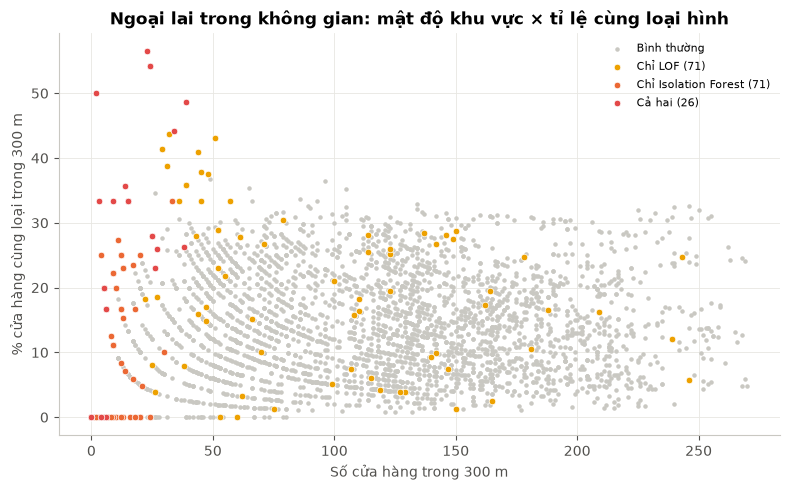

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["n_total_300m"], df["share_own_type_300m"] * 100, s=5, color="#c9c8c2", label="Bình thường")
for name, sel, col in [("Chỉ LOF", df["lof_outlier"] & ~df["if_outlier"], viz.PALETTE[3]),
                       ("Chỉ Isolation Forest", df["if_outlier"] & ~df["lof_outlier"], viz.PALETTE[1]),
                       ("Cả hai", df["outlier_both"], viz.PALETTE[7])]:
    ax.scatter(df.loc[sel, "n_total_300m"], df.loc[sel, "share_own_type_300m"] * 100, s=22, color=col,
               edgecolor="white", linewidth=0.5, label=f"{name} ({sel.sum()})")
ax.set_title("Ngoại lai trong không gian: mật độ khu vực × tỉ lệ cùng loại hình")
ax.set_xlabel("Số cửa hàng trong 300 m"); ax.set_ylabel("% cửa hàng cùng loại trong 300 m")
ax.legend(fontsize=8)
fig.tight_layout(); viz.save_fig(fig, "06_outliers_scatter"); plt.show()

## 2. Gợi ý vị trí mở quán: chấm điểm ô lưới 200 m

Với **một loại hình đầu vào**, mỗi ô lưới 200 m được chấm dựa trên bốn thành phần.

**Đánh giá tại đâu trong ô?** Bản đầu tiên chấm tại *tâm ô* và bị **lệch phân phối**: tâm ô thường rơi vào giữa khối nhà nên có trung vị 1 quán trong 50 m, so với 5 quán ở vị trí cửa hàng thật, và cách quán gần nhất 38 m so với 12 m. Mô hình vì vậy bị hỏi ở những điểm không giống dữ liệu huấn luyện.
Bản hiện tại chấm theo **trung bình bối cảnh của các vị trí mặt tiền có thật trong ô** (các cửa hàng hiện có, đặc trưng đã loại chính điểm), với xác suất là **OOF GroupKFold** của notebook 05, nên không rò rỉ. Mỗi thành phần được chuẩn hóa bằng **hạng phân vị** về [0, 1], rồi cộng có trọng số:

| Thành phần | Đo bằng | Trọng số | Lý do |
|---|---|---|---|
| Nhu cầu / lưu lượng | số cửa hàng trong 300 m (proxy cho mức độ sầm uất) | 0,35 | khách F&B tập trung ở khu đông quán (notebook 03) |
| Ít cạnh tranh | 1 − hạng(**tỉ lệ** quán cùng loại trong 300 m) | 0,30 | dùng *tỉ lệ* thay vì số tuyệt đối, vì số tuyệt đối tăng theo mật độ và sẽ triệt tiêu thành phần nhu cầu |
| Hỗ trợ đồng vị trí | trung bình lift(near:A → self:B) theo cơ cấu xung quanh (ma trận R = 100 m, notebook 04) | 0,15 | luật co-location yếu (lift 0,84–1,26), nên trọng số thấp |
| Mô hình | P(B \| môi trường) / P(B) (notebook 05) | 0,20 | mô hình chỉ tốt hơn ngẫu nhiên vừa phải (AUC ≈ 0,55), nên trọng số vừa |

Chỉ chấm các ô có **≥ 2 cửa hàng** và **≥ 10 cửa hàng trong 300 m**, tức nơi đã có "chợ" F&B. Lý do là ta không có dữ liệu dân cư để đánh giá vùng trống hoàn toàn.

In [6]:
print("Trọng số:", rc.WEIGHTS)
G = rc.score_grid(200)
G.to_csv(TABLES / "grid_recommendations.csv", index=False, encoding="utf-8-sig")
print(f"Số ô 200 m được chấm: {G['cell'].nunique()} | số dòng (ô × loại hình): {len(G)}")
print("Chỉ số phù hợp TB theo loại hình trên các ô (≈ 1 nếu không lệch):", G.groupby("loai_hinh")["phu_hop_lift"].mean().round(2).to_dict())
top5_all = G[G["rank_in_type"] <= 5].sort_values(["loai_hinh", "rank_in_type"])
top5_all[["loai_hinh", "rank_in_type", "cell", "ward_guess", "n_total_300m", "doi_thu_cung_loai_300m",
          "ty_le_cung_loai_300m", "ho_tro_dong_vi_tri", "phu_hop_lift", "score"]].to_csv(
    TABLES / "06_top5_cells_per_type.csv", index=False, encoding="utf-8-sig")

Trọng số: {'demand': 0.35, 'low_competition': 0.3, 'colocation': 0.15, 'model_fit': 0.2}


Số ô 200 m được chấm: 233 | số dòng (ô × loại hình): 2097
Chỉ số phù hợp TB theo loại hình trên các ô (≈ 1 nếu không lệch): {np.str_('Bún/Phở/Cháo'): 1.0, np.str_('Cà phê & nước'): 1.0, np.str_('Cơm'): 0.97, np.str_('Cửa hàng thực phẩm'): 1.03, np.str_('Fast food & Quốc tế'): 0.92, np.str_('Lẩu & Nướng'): 1.06, np.str_('Trà sữa'): 1.01, np.str_('Tráng miệng'): 0.94, np.str_('Ăn vặt & Bánh mì'): 1.04}


In [7]:
SELECTED_TYPE = "Trà sữa"   # <- đổi loại hình đầu vào ở đây
top5 = rc.recommend_locations(SELECTED_TYPE, top=5)
top5[["rank_in_type", "cell", "latitude", "longitude", "ward_guess", "n_stores_in_cell", "n_total_300m", "doi_thu_cung_loai_300m",
      "ty_le_cung_loai_300m", "ho_tro_dong_vi_tri", "phu_hop_lift", "s_demand", "s_low_competition",
      "s_colocation", "s_model_fit", "score"]].round(3)

,rank_in_type,cell,latitude,longitude,ward_guess,n_stores_in_cell,n_total_300m,doi_thu_cung_loai_300m,ty_le_cung_loai_300m,ho_tro_dong_vi_tri,phu_hop_lift,s_demand,s_low_competition,s_colocation,s_model_fit,score
0,1,1011_8886,16.058,108.218,Bình Hiên,41,168.537,10.1,0.060,1.003,1.477,0.910,0.567,0.498,0.948,0.753
1,2,1012_8886,16.058,108.220,Bình Hiên,10,152.600,9.3,0.062,1.004,1.277,0.867,0.541,0.558,0.888,0.727
2,3,1015_8890,16.065,108.225,Phước Ninh,5,139.800,6.4,0.046,0.996,1.489,0.833,0.721,0.077,0.957,0.711
3,4,1012_8887,16.059,108.220,Nam Dương,8,193.875,11.8,0.060,1.001,1.222,0.957,0.562,0.258,0.824,0.707
4,5,1013_8894,16.072,108.221,Hải Châu 1,33,126.818,5.5,0.043,0.998,1.412,0.768,0.742,0.137,0.927,0.698


In [8]:
def recommendation_map(type_group, top=5):
    g = G[G["loai_hinh"] == type_group]
    m = viz.base_map(zoom=14)
    cmap = viz.mpl.colormaps["Blues"]
    fg = folium.FeatureGroup(name="Điểm các ô 200 m")
    smin, smax = g["score"].min(), g["score"].max()
    for _, r in g.iterrows():
        t = (r["score"] - smin) / (smax - smin + 1e-9)
        col = viz.mpl.colors.to_hex(cmap(0.15 + 0.8 * t))
        folium.Rectangle([[r["lat_min"], r["lon_min"]], [r["lat_max"], r["lon_max"]]], color=col, weight=0.5,
                         fill=True, fill_color=col, fill_opacity=0.55,
                         tooltip=(f"Ô {r['cell']} – điểm {r['score']:.2f}<br>{r['n_total_300m']:.0f} quán/300 m, "
                                  f"{r['doi_thu_cung_loai_300m']:.0f} đối thủ cùng loại ({r['ty_le_cung_loai_300m']:.0%})")).add_to(fg)
    fg.add_to(m)
    fg2 = folium.FeatureGroup(name=f"Top {top}")
    for _, r in g.nsmallest(top, "rank_in_type").iterrows():
        folium.Marker([r["latitude"], r["longitude"]],
                      tooltip=f"#{r['rank_in_type']} – điểm {r['score']:.2f} – {r['ward_guess']}",
                      icon=folium.DivIcon(html=f"<div style='background:#e34948;color:white;font-weight:bold;border-radius:50%;"
                                               f"width:22px;height:22px;text-align:center;line-height:22px'>{r['rank_in_type']}</div>")).add_to(fg2)
    fg2.add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    return m

slug = ft.GROUP_SLUG[SELECTED_TYPE]
p = viz.save_map(recommendation_map(SELECTED_TYPE), f"06_recommend_{slug}")
for t in ft.GROUP_ORDER:
    viz.save_map(recommendation_map(t), f"06_recommend_{ft.GROUP_SLUG[t]}")
print("Đã lưu bản đồ gợi ý cho 9 loại hình vào outputs/maps/06_recommend_*.html")
viz.show_map(p, height=550)

Đã lưu bản đồ gợi ý cho 9 loại hình vào outputs/maps/06_recommend_*.html


In [9]:
# Độ nhạy theo trọng số: top-5 có thay đổi nhiều khi đổi trọng số?
def top_cells(weights, t, k=5):
    g = G[G["loai_hinh"] == t]
    s = sum(weights[c] * g[f"s_{c}"] for c in weights)
    return set(g.loc[s.nlargest(k).index, "cell"])

alts = {"Bằng nhau": dict(demand=.25, low_competition=.25, colocation=.25, model_fit=.25),
        "Ưu tiên nhu cầu": dict(demand=.55, low_competition=.25, colocation=.1, model_fit=.1),
        "Ưu tiên ít cạnh tranh": dict(demand=.25, low_competition=.55, colocation=.1, model_fit=.1)}
sens = pd.DataFrame({name: [len(top_cells(rc.WEIGHTS, t) & top_cells(w, t)) / 5 for t in ft.GROUP_ORDER]
                     for name, w in alts.items()}, index=ft.GROUP_ORDER)
print("Tỉ lệ ô trong top-5 giữ nguyên khi đổi trọng số (1 = không đổi):")
sens.round(2)

Tỉ lệ ô trong top-5 giữ nguyên khi đổi trọng số (1 = không đổi):


,Bằng nhau,Ưu tiên nhu cầu,Ưu tiên ít cạnh tranh
Cà phê & nước,0.6,0.4,0.2
Bún/Phở/Cháo,0.2,0.2,0.2
Ăn vặt & Bánh mì,0.8,0.2,0.2
Cơm,1.0,1.0,0.6
Lẩu & Nướng,0.6,0.8,0.8
Trà sữa,0.4,0.6,0.0
Fast food & Quốc tế,0.2,1.0,0.2
Tráng miệng,1.0,0.8,0.6
Cửa hàng thực phẩm,0.8,0.4,0.8


## 3. Gợi ý loại hình cho một vị trí bất kỳ

Hàm `rc.recommend_types(lat, lon)`:
- Nếu có cửa hàng trong vòng 100 m, hàm dùng bối cảnh và xác suất OOF của vị trí mặt tiền gần nhất.
- Nếu không, hàm tính trực tiếp tại điểm đó và **cảnh báo ngoại suy**.

Hàm này cũng gọi được từ dòng lệnh:
```
python -m src.recommend --lat 16.0678 --lon 108.2208
python -m src.recommend --type "Trà sữa" --top 5
```

In [10]:
prof = pd.read_csv(TABLES / "cluster_profiles.csv")
demo_points = {
    f"Tâm hotspot 0 ({prof.loc[0, 'top_streets'].split(' (')[0]})": (prof.loc[0, "center_lat"], prof.loc[0, "center_lon"]),
    f"Tâm hotspot 3 ({prof.loc[3, 'top_streets'].split(' (')[0]})": (prof.loc[3, "center_lat"], prof.loc[3, "center_lon"]),
    "Khu thưa giữa hai cực (16.050, 108.212)": (16.050, 108.212),
    "Ngoài khu có quán (16.030, 108.200)": (16.030, 108.200),
}
for name, (la, lo) in demo_points.items():
    r = rc.recommend_types(la, lo)
    print(f"=== {name} – {r.attrs['context']}")
    print(r.head(4).round(3).to_string(index=False), "\n")

=== Tâm hotspot 0 (Hoàng Diệu) – {'mode': 'gắn vào vị trí cửa hàng gần nhất (cách 42 m)', 'n_total_300m': 223, 'n_total_100m': 14, 'ward': 'Nam Dương'}
          loai_hinh  xac_suat_mo_hinh  phu_hop_lift  doi_thu_cung_loai_300m  ho_tro_dong_vi_tri
                Cơm             0.158         1.339                      22               1.018
Fast food & Quốc tế             0.106         1.105                      24               1.073
      Cà phê & nước             0.148         1.081                      40               0.995
   Ăn vặt & Bánh mì             0.136         1.060                      29               0.993 



=== Tâm hotspot 3 (Nguyễn Chí Thanh) – {'mode': 'gắn vào vị trí cửa hàng gần nhất (cách 37 m)', 'n_total_300m': 148, 'n_total_100m': 25, 'ward': 'Thạch Thang'}
          loai_hinh  xac_suat_mo_hinh  phu_hop_lift  doi_thu_cung_loai_300m  ho_tro_dong_vi_tri
      Cà phê & nước             0.220         1.603                      42               0.997
       Bún/Phở/Cháo             0.172         1.337                      28               1.005
   Ăn vặt & Bánh mì             0.161         1.259                      22               1.000
Fast food & Quốc tế             0.116         1.217                      12               1.066 

=== Khu thưa giữa hai cực (16.050, 108.212) – {'mode': 'NGOẠI SUY – không có cửa hàng nào trong 100 m (gần nhất 120 m)', 'n_total_300m': 40, 'n_total_100m': 0, 'ward': 'Hòa Thuận Tây'}
         loai_hinh  xac_suat_mo_hinh  phu_hop_lift  doi_thu_cung_loai_300m  ho_tro_dong_vi_tri
       Tráng miệng             0.174         2.043                       2    

=== Ngoài khu có quán (16.030, 108.200) – {'mode': 'NGOẠI SUY – không có cửa hàng nào trong 100 m (gần nhất 1013 m)', 'n_total_300m': 0, 'n_total_100m': 0, 'ward': 'Ngoài Hải Châu'}
   loai_hinh  xac_suat_mo_hinh  phu_hop_lift  doi_thu_cung_loai_300m  ho_tro_dong_vi_tri
         Cơm             0.307         2.607                       0                 0.0
 Tráng miệng             0.219         2.566                       0                 0.0
 Lẩu & Nướng             0.214         2.010                       0                 0.0
Bún/Phở/Cháo             0.126         0.977                       0                 0.0 



## 4. Sản phẩm cuối: tệp dữ liệu đã phân tích và GeoJSON

In [11]:
keep = ["storeId", "storeName", "brand", "is_chain", "category", "type_group", "product_types", "n_types",
        "address", "street", "ward_final", "latitude", "longitude", "flag", "rating", "has_rating",
        # phân cụm
        "is_hotspot", "dbscan_label", "hdbscan_label", "km_label", "ward_cluster",
        # bối cảnh không gian
        "n_total_100m", "n_total_300m", "n_total_500m", "n_types_unique_300m", "competitors_same_type_300m",
        "share_own_type_300m", "chain_share_300m", "mean_rating_300m", "dist_nearest_m", "dist_river_m", "dist_hotspot_m",
        # dự đoán
        "pred_type", "pred_top3", "best_fit_type", "best_fit_lift", "own_type_suitability", "pred_source",
        # ngoại lai
        "lof_outlier", "if_outlier", "outlier_both", "outlier_reason"]
analyzed = df[keep].rename(columns={"dbscan_label": "hotspot_id"})
analyzed.to_csv(PROC / "stores_analyzed.csv", index=False, encoding="utf-8-sig")
print("Đã ghi:", (PROC / "stores_analyzed.csv").relative_to(ROOT), analyzed.shape)

dictionary = pd.DataFrame([
    ("storeId", "Mã cửa hàng (gốc)"), ("storeName", "Tên cửa hàng (đã chuẩn hóa Unicode)"),
    ("brand", "Tên thương hiệu chuẩn hóa"), ("is_chain", "Thuộc chuỗi (≥ 2 địa điểm, loại tên chung chung/sạp chợ)"),
    ("category", "FOOD / SHOP"), ("type_group", "Nhóm loại hình chính (9 nhóm + Khác)"),
    ("product_types", "Danh sách nhãn loại hình (phân cách |)"), ("n_types", "Số nhãn loại hình"),
    ("address", "Địa chỉ"), ("street", "Tên đường tách từ địa chỉ"), ("ward_final", "Phường (ưu tiên theo địa chỉ)"),
    ("latitude", "Vĩ độ"), ("longitude", "Kinh độ"), ("flag", "Giá trị gốc"),
    ("rating", "flag/10 – GIẢ ĐỊNH là rating; NaN nếu flag = 0"), ("has_rating", "flag > 0"),
    ("is_hotspot", "Thuộc hotspot DBSCAN (eps 100 m, min_samples 25)"), ("hotspot_id", "Mã hotspot (-1 = ngoài hotspot)"),
    ("hdbscan_label", "Mã cụm HDBSCAN (leaf) (-1 = nhiễu)"), ("km_label", "Mã cụm K-Means (k = 5)"),
    ("ward_cluster", "Cụm phường theo cơ cấu loại hình (1/2)"),
    ("n_total_100m", "Số cửa hàng khác trong 100 m"), ("n_total_300m", "Số cửa hàng khác trong 300 m"),
    ("n_total_500m", "Số cửa hàng khác trong 500 m"), ("n_types_unique_300m", "Số nhóm loại hình khác nhau trong 300 m"),
    ("competitors_same_type_300m", "Số đối thủ cùng nhóm loại hình trong 300 m"),
    ("share_own_type_300m", "Tỉ lệ cửa hàng cùng nhóm trong 300 m"), ("chain_share_300m", "Tỉ lệ chuỗi trong 300 m"),
    ("mean_rating_300m", "Rating TB các quán trong 300 m"), ("dist_nearest_m", "Khoảng cách tới cửa hàng gần nhất (m)"),
    ("dist_river_m", "Khoảng cách Đông–Tây tới sông Hàn xấp xỉ (m)"), ("dist_hotspot_m", "Khoảng cách tới tâm hotspot gần nhất (m)"),
    ("pred_type", "Loại hình mô hình dự đoán (OOF GroupKFold)"), ("pred_top3", "3 loại hình xác suất cao nhất"),
    ("best_fit_type", "Loại hình có chỉ số phù hợp P(c|x)/P(c) cao nhất"), ("best_fit_lift", "Giá trị chỉ số phù hợp đó"),
    ("own_type_suitability", "Chỉ số phù hợp của loại hình hiện tại (> 1 = được môi trường ủng hộ)"),
    ("pred_source", "Nguồn dự đoán"), ("lof_outlier", "Ngoại lai theo LOF"), ("if_outlier", "Ngoại lai theo Isolation Forest"),
    ("outlier_both", "Ngoại lai theo cả hai"), ("outlier_reason", "Đặc trưng lệch nhiều nhất"),
], columns=["column", "description"])
dictionary.to_csv(PROC / "stores_analyzed_dictionary.csv", index=False, encoding="utf-8-sig")
analyzed.head(3).T

Đã ghi: data\processed\stores_analyzed.csv (3208, 42)


,0,1,2
storeId,FOOD07176572,FOOD10740777,FOOD99622263
storeName,Mì Quảng Gà Đá Phú Gia,Cơm Bình Dân Hương Dũng,Bánh Mỳ Miến
brand,mi quang ga da phu gia,com binh dan huong dung,banh my mien
is_chain,False,False,False
category,FOOD,FOOD,FOOD
type_group,Bún/Phở/Cháo,Cơm,Ăn vặt & Bánh mì
product_types,Noodles & Congee,Rice,Bread
n_types,1,1,1
address,"18/1 Lý Thường Kiệt, Phường Thạch Thang, Quận Hải Châu","52 Chi Lăng, Phường Hải Châu 2, Quận Hải Châu","82/10/11 Nguyễn Văn Linh, Phường Nam Dương, Quận Hải Châu, 550000"
street,Lý Thường Kiệt,Chi Lăng,Nguyễn Văn Linh


In [12]:
def to_geojson(features, path):
    path.write_text(json.dumps({"type": "FeatureCollection", "features": features}, ensure_ascii=False), encoding="utf-8")
    print("Đã ghi:", path.relative_to(ROOT), f"({len(features)} feature, {path.stat().st_size / 1024:.0f} KB)")

def clean(v):
    if isinstance(v, (np.integer,)): return int(v)
    if isinstance(v, (np.floating, float)): return None if np.isnan(v) else round(float(v), 6)
    if isinstance(v, (np.bool_,)): return bool(v)
    return v

geo_cols = ["storeId", "storeName", "category", "type_group", "address", "ward_final", "rating", "is_chain", "is_hotspot",
            "hotspot_id", "n_total_300m", "competitors_same_type_300m", "pred_top3", "best_fit_type", "own_type_suitability",
            "outlier_both"]
to_geojson([{"type": "Feature", "geometry": {"type": "Point", "coordinates": [r["longitude"], r["latitude"]]},
             "properties": {c: clean(r[c]) for c in geo_cols}} for _, r in analyzed.iterrows()],
           viz.MAP_DIR / "stores_analyzed.geojson")

hot = []
for _, p in prof.iterrows():
    h = cu.hull_latlon(df[df["dbscan_label"] == p["cluster"]])
    if h:
        ring = [[lo, la] for la, lo in h] + [[h[0][1], h[0][0]]]
        hot.append({"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [ring]},
                    "properties": {k: clean(p[k]) for k in ["cluster", "n_stores", "main_ward", "top_type", "top_type_pct",
                                                             "mean_rating", "top_streets"]}})
to_geojson(hot, viz.MAP_DIR / "hotspots.geojson")

cells = []
for c, g in G.groupby("cell"):
    r0 = g.iloc[0]
    ring = [[r0["lon_min"], r0["lat_min"]], [r0["lon_max"], r0["lat_min"]], [r0["lon_max"], r0["lat_max"]],
            [r0["lon_min"], r0["lat_max"]], [r0["lon_min"], r0["lat_min"]]]
    best = g.sort_values("score", ascending=False).iloc[0]
    props = {"cell": c, "ward": r0["ward_guess"], "n_total_300m": clean(r0["n_total_300m"]),
             "best_type": best["loai_hinh"], "best_score": clean(best["score"])}
    props.update({f"score_{ft.GROUP_SLUG[t]}": clean(s) for t, s in zip(g["loai_hinh"], g["score"])})
    props.update({f"rank_{ft.GROUP_SLUG[t]}": clean(s) for t, s in zip(g["loai_hinh"], g["rank_in_type"])})
    cells.append({"type": "Feature", "geometry": {"type": "Polygon", "coordinates": [ring]}, "properties": props})
to_geojson(cells, viz.MAP_DIR / "grid_recommendations.geojson")

Đã ghi: outputs\maps\stores_analyzed.geojson (3208 feature, 1984 KB)
Đã ghi: outputs\maps\hotspots.geojson (14 feature, 9 KB)


Đã ghi: outputs\maps\grid_recommendations.geojson (233 feature, 187 KB)


**Tích hợp web (React + Leaflet, dự án `D:\MapSiteDaNang_FE`):** chép 3 file `outputs/maps/*.geojson` vào thư mục `public/` rồi nạp bằng `fetch()` + `L.geoJSON()`, hoặc `<GeoJSON>` nếu dùng react-leaflet.
- `grid_recommendations.geojson`: tô màu ô theo `score_<loại>` (ví dụ `score_milktea`), hiển thị `rank_<loại>` trong popup.
- `hotspots.geojson`: vẽ polygon các hotspot.
- `stores_analyzed.geojson`: vẽ điểm cửa hàng; popup gồm `type_group`, `pred_top3`, `own_type_suitability`.

## 5. Feedback – Phản hồi và vòng lặp cải tiến

Theo quy trình DAM501, bước Feedback đưa kết quả trở lại các bước **Analytic approach** và **Data requirements**.

### 5.1. Các vòng lặp đã thực hiện trong dự án

| Phát hiện (ở bước) | Phản hồi | Quay về bước |
|---|---|---|
| `flag` chỉ nằm trong 30–45, một nửa bằng 0, ý nghĩa chưa chắc chắn (Data understanding) | Đổi mục tiêu dự đoán từ *rating cao/thấp* sang *loại hình phù hợp vị trí* | Analytic approach |
| `productType` có 51 nhãn, trong đó có nhãn huy hiệu Grab (Data understanding) | Tách huy hiệu, gộp đồng nghĩa, chuẩn hóa còn 20 nhãn và 9 nhóm | Data preprocessing |
| Trường `ward` khớp với địa chỉ chỉ 48,5% (Data understanding) | Ưu tiên phường lấy từ địa chỉ | Data preprocessing |
| "Chain" bị nhiễu bởi tên món chung chung (Preprocessing) | Thêm danh sách tên chung chung và sạp chợ | Data preprocessing |
| DBSCAN với eps 150–300 m bị nối chuỗi (Model) | Nâng ngưỡng mật độ (min_samples = 25) và dùng HDBSCAN `leaf` | Model |
| Luật lưới bị nhiễu bởi mật độ (Model) | Chuyển sang luật lân cận lấy cửa hàng làm tâm | Analytic approach |
| CV ngẫu nhiên cho kết quả đẹp giả (Evaluation) | Dùng GroupKFold không gian làm thước đo chính; bỏ tọa độ thô khỏi đặc trưng | Evaluation, Preprocessing |
| Mô hình chỉ tốt hơn ngẫu nhiên vừa phải (Evaluation) | Điểm vị trí kết hợp 4 thành phần, mô hình chỉ chiếm 20% trọng số | Deployment |
| Xác suất của mô hình cân bằng lớp làm lệch chỉ số phù hợp (Deployment) | Chỉ số phù hợp so với xác suất TB của mô hình thay vì tỉ lệ nền | Deployment |
| Chấm điểm tại tâm ô bị lệch phân phối: tâm ô ít quán lân cận hơn hẳn vị trí cửa hàng thật (Deployment) | Chấm theo vị trí mặt tiền thật; gắn tọa độ truy vấn vào cửa hàng gần nhất (≤ 100 m), ngoài ra cảnh báo ngoại suy | Deployment |
| Ngoại lai lộ ra lỗi tọa độ còn sót, vd "Mạnh Phố Cổ" ghi Hải Châu 1 nhưng tọa độ ở Cẩm Lệ (Deployment) | Vòng sau bổ sung bước đối chiếu tọa độ với địa chỉ (geocoding) | Data preprocessing |

### 5.2. Phản hồi cần thu thập sau triển khai

- **Từ người dùng công cụ** (chủ quán, nhà đầu tư): các ô top-5 có hợp lý trên thực địa không? Giá thuê ra sao? Ghi lại vào một bảng đánh giá gồm ô, loại hình, đánh giá đúng/sai và ghi chú, để điều chỉnh trọng số `rc.WEIGHTS`.
- **Theo thời gian:** crawl lại sau 6–12 tháng. Quán nào **đóng cửa** hoặc **mới mở** chính là nhãn "thành công / thất bại" thật, giúp chuyển bài toán từ *mô tả cái đang có* sang *dự đoán cái sẽ sống sót*.

### 5.3. Yêu cầu dữ liệu cho vòng tiếp theo (quay lại bước Data requirements)

1. **Nhu cầu:** dân số / mật độ dân cư theo phường, vị trí trường học, văn phòng, chợ, bệnh viện, điểm du lịch (OpenStreetMap / Overpass), lưu lượng giao thông.
2. **Chất lượng & mức độ quan tâm:** rating thật kèm số lượt đánh giá. Có thể ghép với Google Maps (`src/scrape_gmaps.py`, chỉ dùng cho học tập) theo tên chuẩn hóa và khoảng cách < 50 m, từ đó kiểm chứng giả định `rating = flag/10`.
3. **Kinh tế:** khoảng giá món, giá thuê mặt bằng.
4. **Thời gian:** giờ mở cửa, để tách quán buổi sáng, quán buổi tối và quán đêm.
5. **Mở rộng phạm vi:** các quận lân cận (Thanh Khê, Sơn Trà), để mô hình học được nhiều kiểu môi trường hơn và tránh hiệu ứng biên.